# 60 · Coupled fields

**Question.** Do both forms carry a coupled system's fields, and what does the descriptor's mass form buy over carrying each field's derivative as a block of its own?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p6_build", "p6_stateprep", "p6_t3")
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p6_build: 374 records, 374 ok
p6_stateprep: 162 records, 162 ok
p6_t3: 140 records, 140 ok


In [2]:
from IPython.display import Markdown, display


def rows(campaign, **match):
    """Return a campaign's ok rows of R7 whose columns equal every match."""
    return [
        r
        for r in results.rows(campaign)
        if r["status"] == "ok" and r["problem"] == "R7" and all(r[k] == v for k, v in match.items())
    ]


builds = {
    "standard": rows("p6_build", label="", regime="standard"),
    "descriptor": rows("p6_build", label="", regime="descriptor"),
    "chain ablation": rows("p6_build", label="chain"),
}
estimates = {form: rows("p6_t3", regime=form) for form in ("standard", "descriptor")}
prepared = [r for r in rows("p6_stateprep") if not r["label"] and r["trusted"]]


def at(series, n):
    """Return a series' row at n."""
    return next(r for r in series if r["n"] == n)


top = max(r["n"] for r in builds["chain ablation"])
gain = at(builds["descriptor"], top)["gap"] / at(builds["chain ablation"], top)["gap"]
shared = max({r["n"] for r in estimates["standard"]} & {r["n"] for r in estimates["descriptor"]})
degrees = {form: at(series, shared)["degree"] for form, series in estimates.items()}
lines = [
    f"- At n = {top} the field's error is {at(builds['standard'], top)['field_err_linf']:.1e} in "
    f"the standard form and {at(builds['descriptor'], top)['field_err_linf']:.1e} in the "
    f"descriptor; the mass form's gap is {gain:.2f} times the chain's.",
    f"- Every one of {len(prepared)} trusted preparations is within its tolerance "
    f"({max(r['infidelity'] for r in prepared):.1e} at worst).",
    f"- At n = {shared} the filter's degree is {degrees['standard']:,} in the standard form and "
    f"{degrees['descriptor']:,} in the descriptor.",
]
display(Markdown("\n".join(lines)))

- At n = 9 the field's error is 3.0e-11 in the standard form and 1.2e-11 in the descriptor; the mass form's gap is 2.10 times the chain's.
- Every one of 12 trusted preparations is within its tolerance (2.5e-12 at worst).
- At n = 9 the filter's degree is 5,732,462 in the standard form and 21,143 in the descriptor.

The decoded fields' error against the exact solution, in both forms and the chain ablation.

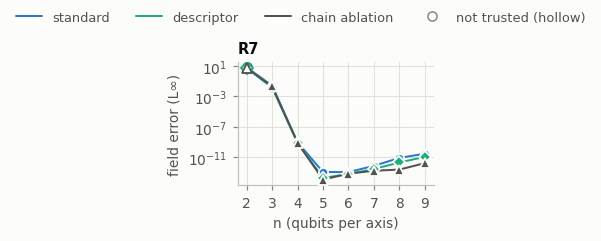

In [3]:
plotting.by_resolution(builds, "field_err_linf", "field error (L∞)");

The gap on the physical subspace: the mass form carries no derivative block, and its gap is
the chain's times a constant.

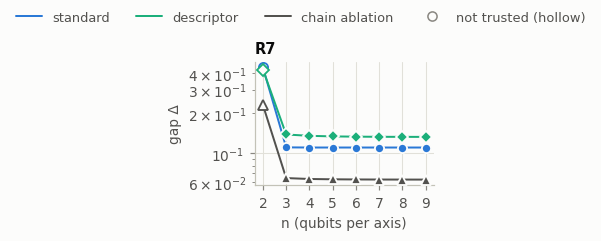

In [4]:
plotting.by_resolution(builds, "gap", "gap Δ");

The minimax filter's degree a preparation needs (T3), in both forms.

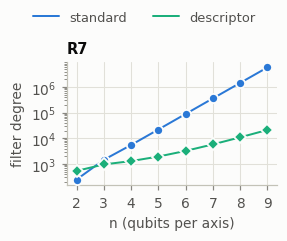

In [5]:
plotting.by_resolution(estimates, "degree", "filter degree");

**What this does not show.** R7 is linear, so its fields need no lift; the Carleman lift of a
nonlinear system is notebooks 61 and 62. The chain ablation is classical only: its circuit is
not built.